In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

In [2]:
df_exp=pd.read_csv(r"D:\To_Program\Project\ML\data\Housing.csv")

In [3]:
df_exp.info()

<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


In [4]:
df_exp.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [5]:
df_exp.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [6]:
df_exp.dtypes

price               int64
area                int64
bedrooms            int64
bathrooms           int64
stories             int64
mainroad              str
guestroom             str
basement              str
hotwaterheating       str
airconditioning       str
parking             int64
prefarea              str
furnishingstatus      str
dtype: object

In [7]:
df_exp.select_dtypes(exclude='number').nunique()

mainroad            2
guestroom           2
basement            2
hotwaterheating     2
airconditioning     2
prefarea            2
furnishingstatus    3
dtype: int64

In [8]:
df_exp.shape

(545, 13)

In [9]:
df_exp.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [10]:
df_exp.duplicated().sum()

np.int64(0)

In [11]:
for col in df_exp.select_dtypes(exclude='number').columns:
    print(col)
    print(df_exp[col].value_counts())
    print()

mainroad
mainroad
yes    468
no      77
Name: count, dtype: int64

guestroom
guestroom
no     448
yes     97
Name: count, dtype: int64

basement
basement
no     354
yes    191
Name: count, dtype: int64

hotwaterheating
hotwaterheating
no     520
yes     25
Name: count, dtype: int64

airconditioning
airconditioning
no     373
yes    172
Name: count, dtype: int64

prefarea
prefarea
no     417
yes    128
Name: count, dtype: int64

furnishingstatus
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64



In [12]:
df_exp.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [13]:
binary_cols = ['mainroad', 'guestroom', 'basement',
               'hotwaterheating', 'airconditioning', 'prefarea']

df_bin = df_exp.copy()
df_bin[binary_cols] = df_bin[binary_cols].apply(lambda s: s.map({'yes': 1, 'no': 0}))

df_bin.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


In [14]:
# Version A: ordinal encoding for furnishingstatus (same idea as before)
df_exp = df_bin.copy()
df_exp['furnishingstatus'] = df_exp['furnishingstatus'].map(
    {'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2}
)

# Version B: one-hot encoding, dropping the reference category
df_onehot = pd.get_dummies(df_bin, columns=['furnishingstatus'],
                           drop_first=True, dtype=int)

print(df_exp.shape, df_onehot.shape)
print(df_onehot.columns.tolist())

(545, 13) (545, 14)
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']


In [15]:
# Safety check: .map() turns any unmapped value into NaN, so confirm nothing was lost
print(df_exp.isnull().sum().sum(), df_onehot.isnull().sum().sum())
df_onehot.head()

0 0


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [16]:
from sklearn.model_selection import train_test_split

def split(df):
    X = df.drop('price', axis=1)
    y = df['price']
    return train_test_split(X, y, test_size=0.3, random_state=62)

Xo_train, Xo_test, yo_train, yo_test = split(df_exp)
Xh_train, Xh_test, yh_train, yh_test = split(df_onehot)

print(Xo_train.shape, Xo_test.shape)
print((yo_train.index == yh_train.index).all())   # same houses in both splits?

(381, 12) (164, 12)
True


In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate(model, X_train, X_test, y_train, y_test, name):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    return {
        'Experiment': name,
        'MAE': mean_absolute_error(y_test, pred),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R2': r2_score(y_test, pred),
    }

In [18]:
results = []
results.append(evaluate(LinearRegression(), Xo_train, Xo_test, yo_train, yo_test,
                        '1: LinReg, ordinal furnishing, no scaling'))
results.append(evaluate(LinearRegression(), Xh_train, Xh_test, yh_train, yh_test,
                        '2: LinReg, one-hot furnishing, no scaling'))

import pandas as pd
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.DataFrame(results)

,Experiment,MAE,MSE,RMSE,R2
0,"1: LinReg, ordinal furnishing, no scaling","780,013.6644","1,141,911,601,013.1992","1,068,602.6394",0.6704
1,"2: LinReg, one-hot furnishing, no scaling","783,065.3109","1,170,403,709,730.8777","1,081,851.9814",0.6622


In [19]:
from sklearn.model_selection import KFold, cross_validate

kf = KFold(n_splits=5, shuffle=True, random_state=62)
scoring = {'r2': 'r2',
           'mae': 'neg_mean_absolute_error',
           'rmse': 'neg_root_mean_squared_error'}

def cv_report(X_train, y_train, name):
    cv = cross_validate(LinearRegression(), X_train, y_train, cv=kf, scoring=scoring)
    return {
        'Experiment': name,
        'R2 mean': cv['test_r2'].mean(),
        'R2 std': cv['test_r2'].std(),
        'MAE mean': -cv['test_mae'].mean(),
        'RMSE mean': -cv['test_rmse'].mean(),
    }

cv_results = [
    cv_report(Xo_train, yo_train, '1: ordinal furnishing'),
    cv_report(Xh_train, yh_train, '2: one-hot furnishing'),
]
pd.DataFrame(cv_results)

,Experiment,R2 mean,R2 std,MAE mean,RMSE mean
0,1: ordinal furnishing,0.6507,0.0473,"806,948.7941","1,093,594.7529"
1,2: one-hot furnishing,0.6470,0.0373,"814,923.5534","1,100,591.2387"


In [20]:
train_df = df_exp.loc[Xo_train.index]

def outlier_summary(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    z = (s - s.mean()) / s.std()
    return {
        'IQR low': low, 'IQR high': high,
        'IQR flagged': int(((s < low) | (s > high)).sum()),
        'Z>3 flagged': int((z.abs() > 3).sum()),
        'skew': s.skew(),
    }

pd.DataFrame({c: outlier_summary(train_df[c]) for c in ['price', 'area']})

,price,area
IQR low,"87,500.0000",-600.0000
IQR high,"8,907,500.0000","10,600.0000"
IQR flagged,14.0000,7.0000
Z>3 flagged,4.0000,5.0000
skew,1.2644,1.2198


C:\Users\raash\AppData\Local\Temp\ipykernel_11944\2871740165.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, i].boxplot(train_df[c], vert=False)
C:\Users\raash\AppData\Local\Temp\ipykernel_11944\2871740165.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0, i].boxplot(train_df[c], vert=False)


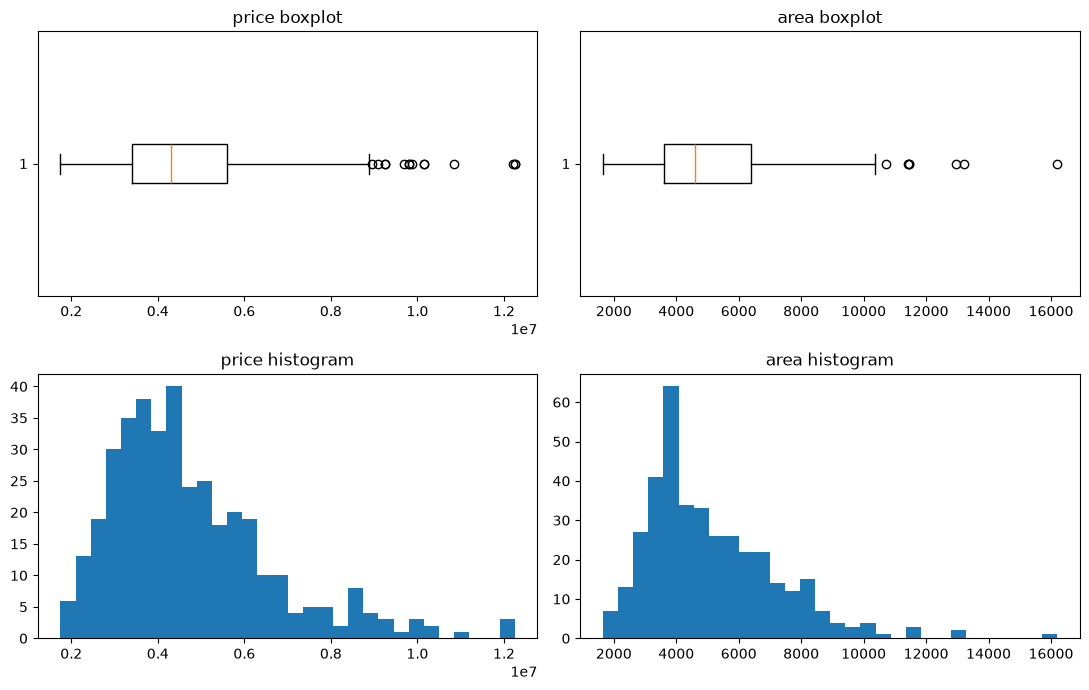

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, c in enumerate(['price', 'area']):
    axes[0, i].boxplot(train_df[c], vert=False)
    axes[0, i].set_title(f'{c} boxplot')
    axes[1, i].hist(train_df[c], bins=30)
    axes[1, i].set_title(f'{c} histogram')
plt.tight_layout()
plt.show()

In [22]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

def run_cv(X, y, treatment='none'):
    r2s, maes, kept = [], [], []
    for tr, val in kf.split(X):
        X_tr, y_tr = X.iloc[tr].copy(), y.iloc[tr].copy()
        X_val, y_val = X.iloc[val].copy(), y.iloc[val]

        a_lo, a_hi = iqr_bounds(X_tr['area'])      # fences from training part only
        p_lo, p_hi = iqr_bounds(y_tr)

        if treatment == 'remove':
            keep = X_tr['area'].between(a_lo, a_hi) & y_tr.between(p_lo, p_hi)
            X_tr, y_tr = X_tr[keep], y_tr[keep]
        elif treatment == 'cap':
            X_tr['area'] = X_tr['area'].clip(a_lo, a_hi)
            X_val['area'] = X_val['area'].clip(a_lo, a_hi)   # feature rule applies to new data too
            y_tr = y_tr.clip(p_lo, p_hi)                     # target is only ever treated in training

        pred = LinearRegression().fit(X_tr, y_tr).predict(X_val)
        r2s.append(r2_score(y_val, pred))
        maes.append(mean_absolute_error(y_val, pred))
        kept.append(len(X_tr))
    return {'Treatment': treatment, 'R2 mean': np.mean(r2s), 'R2 std': np.std(r2s),
            'MAE mean': np.mean(maes), 'Avg train rows': np.mean(kept)}

pd.DataFrame([run_cv(Xo_train, yo_train, t) for t in ['none', 'remove', 'cap']])

,Treatment,R2 mean,R2 std,MAE mean,Avg train rows
0,none,0.6507,0.0473,"806,948.7941",304.8000
1,remove,0.6445,0.0472,"796,420.9183",290.0000
2,cap,0.6452,0.0503,"805,636.6931",304.8000


In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler

scalers = {
    'none': None,
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'MaxAbsScaler': MaxAbsScaler(),
}

rows = []
for name, sc in scalers.items():
    model = LinearRegression() if sc is None else make_pipeline(sc, LinearRegression())
    cv = cross_validate(model, Xo_train, yo_train, cv=kf, scoring=scoring)
    rows.append({'Scaler': name,
                 'R2 mean': cv['test_r2'].mean(),
                 'R2 std': cv['test_r2'].std(),
                 'MAE mean': -cv['test_mae'].mean()})

pd.DataFrame(rows)

,Scaler,R2 mean,R2 std,MAE mean
0,none,0.6507,0.0473,"806,948.7941"
1,StandardScaler,0.6507,0.0473,"806,948.7941"
2,MinMaxScaler,0.6507,0.0473,"806,948.7941"
3,RobustScaler,0.6507,0.0473,"806,948.7941"
4,MaxAbsScaler,0.6507,0.0473,"806,948.7941"


In [24]:
from sklearn.compose import TransformedTargetRegressor, ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer

def make_model(target=None, area=None):
    if area == 'log':
        feats = ColumnTransformer(
            [('area', FunctionTransformer(np.log), ['area'])],
            remainder='passthrough')
        base = make_pipeline(feats, LinearRegression())
    else:
        base = LinearRegression()

    if target == 'log':
        return TransformedTargetRegressor(base, func=np.log, inverse_func=np.exp)
    if target in ('box-cox', 'yeo-johnson'):
        return TransformedTargetRegressor(base, transformer=PowerTransformer(method=target))
    return base

rows = []
for target in [None, 'log', 'box-cox', 'yeo-johnson']:
    for area in [None, 'log']:
        cv = cross_validate(make_model(target, area), Xo_train, yo_train,
                            cv=kf, scoring=scoring)
        rows.append({'Target': target, 'Area': area,
                     'R2 mean': cv['test_r2'].mean(),
                     'R2 std': cv['test_r2'].std(),
                     'MAE mean': -cv['test_mae'].mean()})

pd.DataFrame(rows)

,Target,Area,R2 mean,R2 std,MAE mean
0,NaN,NaN,0.6507,0.0473,"806,948.7941"
1,NaN,log,0.6518,0.0493,"801,849.5073"
2,log,NaN,0.6691,0.0534,"776,592.8745"
3,log,log,0.6741,0.0616,"767,321.9213"
4,box-cox,NaN,0.6633,0.0491,"783,810.8907"
5,box-cox,log,0.6704,0.0591,"771,420.4492"
6,yeo-johnson,NaN,0.6633,0.0491,"783,810.8979"
7,yeo-johnson,log,0.6704,0.0591,"771,420.4540"


In [25]:
from sklearn.model_selection import cross_val_score

base = cross_val_score(make_model(None, None),   Xo_train, yo_train, cv=kf, scoring='r2')
logt = cross_val_score(make_model('log', None),  Xo_train, yo_train, cv=kf, scoring='r2')
both = cross_val_score(make_model('log', 'log'), Xo_train, yo_train, cv=kf, scoring='r2')

print(pd.DataFrame({'baseline': base, 'log target': logt, 'log target + log area': both}).round(4))
print('log target beats baseline in', (logt > base).sum(), 'of 5 folds')
print('log target + log area beats log target in', (both > logt).sum(), 'of 5 folds')

   baseline  log target  log target + log area
0    0.6959      0.6994                 0.7048
1    0.7174      0.7520                 0.7638
2    0.6195      0.5974                 0.5796
3    0.6256      0.6636                 0.6803
4    0.5950      0.6331                 0.6422
log target beats baseline in 4 of 5 folds
log target + log area beats log target in 4 of 5 folds


In [27]:
train_eda = df_exp.loc[Xo_train.index].copy()
train_eda['log_price'] = np.log(train_eda['price'])
train_eda['log_area'] = np.log(train_eda['area'])

# 1. Correlation of each feature with log(price)
corr = (train_eda.drop(columns=['price', 'area'])
        .corr()['log_price'].drop('log_price').sort_values(ascending=False))
print(corr.round(3))

# 2. Strongest feature-feature correlations
fc = train_eda.drop(columns=['price', 'area', 'log_price']).corr().abs()
pairs = fc.where(np.triu(np.ones(fc.shape), k=1).astype(bool)).stack()
print()
print(pairs.sort_values(ascending=False).head(6).round(3))

log_area           0.5650
bathrooms          0.4820
airconditioning    0.4230
stories            0.3960
bedrooms           0.3880
parking            0.3760
furnishingstatus   0.3620
prefarea           0.3270
mainroad           0.2940
guestroom          0.2690
basement           0.2190
hotwaterheating    0.1190
Name: log_price, dtype: float64

bedrooms   stories     0.4040
guestroom  basement    0.3730
bedrooms   bathrooms   0.3570
parking    log_area    0.3510
mainroad   log_area    0.3360
bathrooms  stories     0.2800
dtype: float64


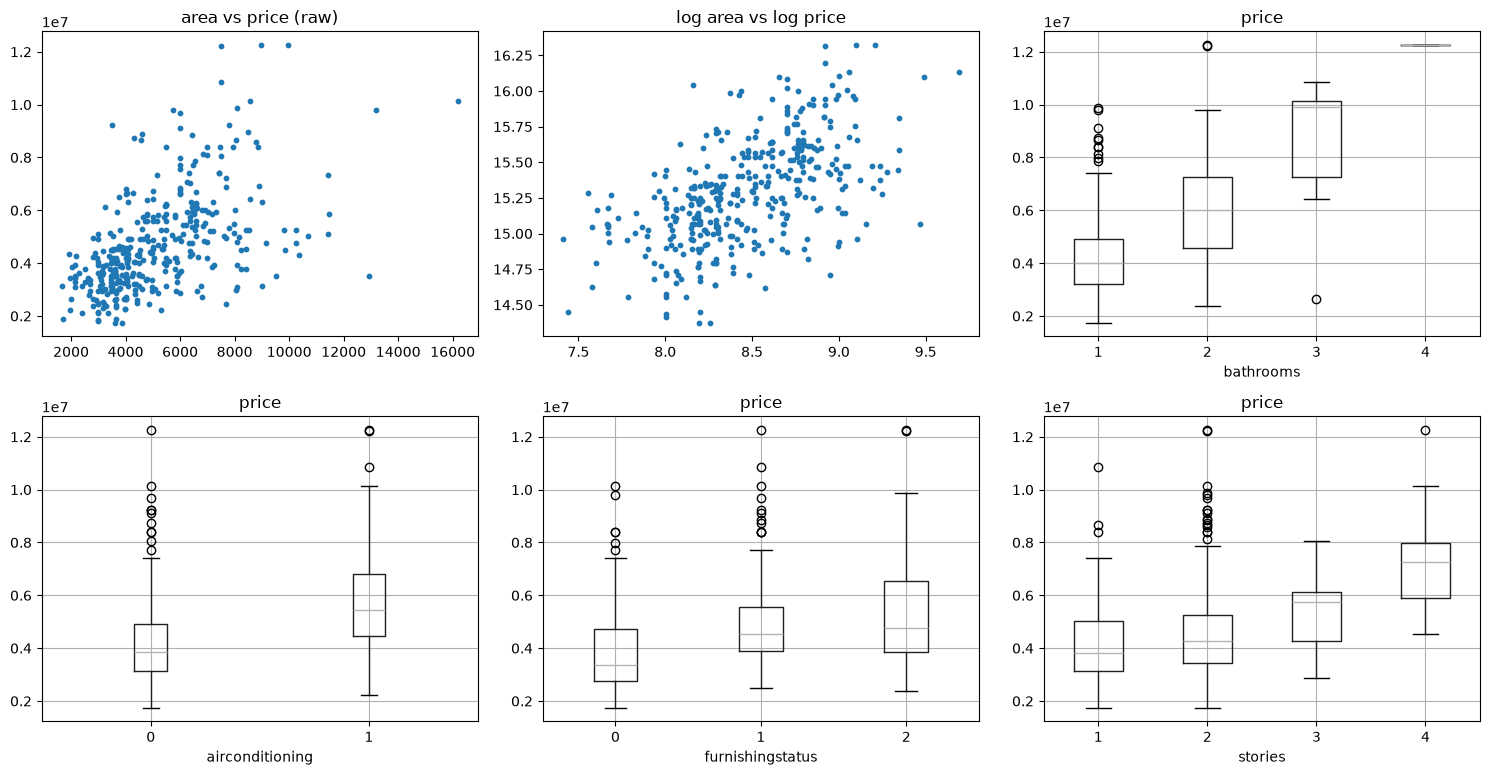

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

axes[0, 0].scatter(train_eda['area'], train_eda['price'], s=10)
axes[0, 0].set_title('area vs price (raw)')

axes[0, 1].scatter(train_eda['log_area'], train_eda['log_price'], s=10)
axes[0, 1].set_title('log area vs log price')

train_eda.boxplot(column='price', by='bathrooms', ax=axes[0, 2])
train_eda.boxplot(column='price', by='airconditioning', ax=axes[1, 0])
train_eda.boxplot(column='price', by='furnishingstatus', ax=axes[1, 1])
train_eda.boxplot(column='price', by='stories', ax=axes[1, 2])

plt.suptitle('')
plt.tight_layout()
plt.show()

In [29]:
def log_area_version(X):
    X = X.copy()
    X['area'] = np.log(X['area'])
    return X.rename(columns={'area': 'log_area'})

base = log_area_version(Xo_train)

sets = {
    'F0 baseline (log area, log target)': base,
    'F1 furnishing one-hot':              log_area_version(Xh_train),
    'F2 stories as categories':           pd.get_dummies(base, columns=['stories'],
                                                         drop_first=True, dtype=int),
    'F3 + log area per bedroom':          base.assign(
                                              log_area_per_bedroom=np.log(Xo_train['area'] / Xo_train['bedrooms'])),
    'F4 + log area x airconditioning':    base.assign(
                                              area_x_ac=base['log_area'] * base['airconditioning']),
}

fold_r2, rows = {}, []
for name, X in sets.items():
    model = TransformedTargetRegressor(LinearRegression(), func=np.log, inverse_func=np.exp)
    cv = cross_validate(model, X, yo_train, cv=kf, scoring=scoring)
    fold_r2[name] = cv['test_r2']
    rows.append({'Feature set': name,
                 'R2 mean': cv['test_r2'].mean(),
                 'R2 std': cv['test_r2'].std(),
                 'MAE mean': -cv['test_mae'].mean()})

out = pd.DataFrame(rows)
b = fold_r2[list(sets)[0]]
out['Folds beating F0'] = [int((fold_r2[n] > b).sum()) for n in sets]
out

,Feature set,R2 mean,R2 std,MAE mean,Folds beating F0
0,"F0 baseline (log area, log target)",0.6741,0.0616,"767,321.9213",0
1,F1 furnishing one-hot,0.6687,0.0467,"764,411.8441",2
2,F2 stories as categories,0.6653,0.0654,"773,589.9529",0
3,F3 + log area per bedroom,0.6743,0.0641,"766,058.8926",4
4,F4 + log area x airconditioning,0.6729,0.0612,"767,696.2880",2


In [30]:
from sklearn.feature_selection import SelectKBest, f_regression

def log_target_model(inner):
    return TransformedTargetRegressor(inner, func=np.log, inverse_func=np.exp)

base = log_area_version(Xo_train)

# 1. How "rare" is each flag?
flags = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
print(base[flags].mean().round(3))
print()

# 2. Drop-one ablation
full = cross_validate(log_target_model(LinearRegression()), base, yo_train, cv=kf, scoring=scoring)
b_r2 = full['test_r2']

rows = []
for col in base.columns:
    cv = cross_validate(log_target_model(LinearRegression()), base.drop(columns=col),
                        yo_train, cv=kf, scoring=scoring)
    rows.append({'Dropped': col,
                 'R2 mean': cv['test_r2'].mean(),
                 'Change vs full': cv['test_r2'].mean() - b_r2.mean(),
                 'MAE mean': -cv['test_mae'].mean(),
                 'Folds better without': int((cv['test_r2'] > b_r2).sum())})
print(pd.DataFrame(rows).sort_values('Change vs full', ascending=False).to_string(index=False))
print()

# 3. SelectKBest sweep, inside the pipeline
rows = []
for k in range(3, 13):
    model = log_target_model(make_pipeline(SelectKBest(f_regression, k=k), LinearRegression()))
    cv = cross_validate(model, base, yo_train, cv=kf, scoring=scoring)
    rows.append({'k': k, 'R2 mean': cv['test_r2'].mean(), 'MAE mean': -cv['test_mae'].mean()})
print(pd.DataFrame(rows).to_string(index=False))

mainroad          0.8710
guestroom         0.1630
basement          0.3410
hotwaterheating   0.0600
airconditioning   0.3150
prefarea          0.2340
dtype: float64

         Dropped  R2 mean  Change vs full     MAE mean  Folds better without
       guestroom   0.6789          0.0048 758,280.6622                     2
        mainroad   0.6688         -0.0054 774,810.1399                     0
        bedrooms   0.6684         -0.0058 772,993.6930                     1
         parking   0.6650         -0.0091 774,175.5032                     1
        basement   0.6607         -0.0134 779,322.3606                     0
furnishingstatus   0.6598         -0.0144 782,963.4889                     2
 hotwaterheating   0.6571         -0.0171 784,128.8397                     1
        prefarea   0.6473         -0.0269 805,911.0489                     1
         stories   0.6434         -0.0307 804,746.1838                     2
 airconditioning   0.6350         -0.0392 806,744.9820          

In [31]:
from sklearn.model_selection import RepeatedKFold

rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=62)
base = log_area_version(Xo_train)

def evaluate_cv(model, X, name):
    cv = cross_validate(model, X, yo_train, cv=rkf, scoring=scoring)
    return {'Model': name,
            'R2 mean': cv['test_r2'].mean(),
            'R2 std': cv['test_r2'].std(),
            'MAE mean': -cv['test_mae'].mean(),
            'RMSE mean': -cv['test_rmse'].mean()}

results_v2 = [evaluate_cv(log_target_model(LinearRegression()), base,
                          'Linear (log target, log area)')]
pd.DataFrame(results_v2)

,Model,R2 mean,R2 std,MAE mean,RMSE mean
0,"Linear (log target, log area)",0.6616,0.0599,"773,037.5618","1,067,923.9595"


In [32]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV

ridge = log_target_model(make_pipeline(StandardScaler(),
            RidgeCV(alphas=np.logspace(-3, 3, 50))))
lasso = log_target_model(make_pipeline(StandardScaler(),
            LassoCV(cv=5, max_iter=20000)))
enet  = log_target_model(make_pipeline(StandardScaler(),
            ElasticNetCV(l1_ratio=[0.1, 0.5, 0.7, 0.9, 0.95, 1], cv=5, max_iter=20000)))

results_11a = [
    evaluate_cv(LinearRegression(), Xo_train, 'Plain linear (raw price, raw area)'),
    evaluate_cv(log_target_model(LinearRegression()), base, 'Linear (log target, log area)'),
    evaluate_cv(ridge, base, 'Ridge (log target, log area)'),
    evaluate_cv(lasso, base, 'Lasso (log target, log area)'),
    evaluate_cv(enet,  base, 'ElasticNet (log target, log area)'),
]
pd.DataFrame(results_11a)

,Model,R2 mean,R2 std,MAE mean,RMSE mean
0,"Plain linear (raw price, raw area)",0.6394,0.0571,"811,161.5986","1,101,064.7101"
1,"Linear (log target, log area)",0.6616,0.0599,"773,037.5618","1,067,923.9595"
2,"Ridge (log target, log area)",0.6608,0.0576,"769,479.7963","1,070,454.6522"
3,"Lasso (log target, log area)",0.6612,0.0593,"773,026.1049","1,068,968.4610"
4,"ElasticNet (log target, log area)",0.6601,0.0575,"771,656.1856","1,071,508.8899"


In [33]:
lasso_fit = log_target_model(make_pipeline(StandardScaler(), LassoCV(cv=5, max_iter=20000)))
lasso_fit.fit(base, yo_train)

lasso_inner = lasso_fit.regressor_.named_steps['lassocv']
print('chosen alpha:', round(lasso_inner.alpha_, 5))
print(pd.Series(lasso_inner.coef_, index=base.columns).round(4).sort_values())

chosen alpha: 0.00079
guestroom          0.0207
mainroad           0.0258
bedrooms           0.0320
parking            0.0339
basement           0.0399
hotwaterheating    0.0447
prefarea           0.0596
furnishingstatus   0.0605
airconditioning    0.0727
stories            0.0760
bathrooms          0.0766
log_area           0.1172
dtype: float64


In [34]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

tree_models = {
    'Tree (unconstrained)':       DecisionTreeRegressor(random_state=62),
    'Tree (depth 4, leaf >= 10)': DecisionTreeRegressor(max_depth=4, min_samples_leaf=10, random_state=62),
    'Random Forest':              RandomForestRegressor(n_estimators=300, random_state=62, n_jobs=-1),
    'Gradient Boosting':          GradientBoostingRegressor(random_state=62),
}

results_11b = []
for name, m in tree_models.items():
    results_11b.append(evaluate_cv(m, Xo_train, f'{name}, raw price'))
    results_11b.append(evaluate_cv(log_target_model(m), Xo_train, f'{name}, log price'))

pd.DataFrame(results_11b)

,Model,R2 mean,R2 std,MAE mean,RMSE mean
0,"Tree (unconstrained), raw price",0.1320,0.2557,"1,189,655.4091","1,686,112.6787"
1,"Tree (unconstrained), log price",0.1768,0.1877,"1,173,155.5514","1,653,102.3551"
2,"Tree (depth 4, leaf >= 10), raw price",0.4290,0.0844,"1,007,030.6719","1,385,509.3861"
3,"Tree (depth 4, leaf >= 10), log price",0.4683,0.0704,"960,913.0912","1,340,497.0761"
4,"Random Forest, raw price",0.5720,0.1047,"847,727.3020","1,192,400.6549"
5,"Random Forest, log price",0.5681,0.0925,"843,767.8192","1,202,746.9666"
6,"Gradient Boosting, raw price",0.5856,0.1050,"822,117.6928","1,173,424.9799"
7,"Gradient Boosting, log price",0.5958,0.0675,"813,497.3539","1,168,264.7527"


In [35]:
from sklearn.model_selection import RandomizedSearchCV

inner_cv = KFold(n_splits=5, shuffle=True, random_state=1)

gb_params = {
    'regressor__learning_rate':    [0.01, 0.03, 0.05, 0.1],
    'regressor__n_estimators':     [100, 200, 400],
    'regressor__max_depth':        [1, 2, 3],
    'regressor__min_samples_leaf': [3, 5, 10, 20],
    'regressor__subsample':        [0.6, 0.8, 1.0],
}
rf_params = {
    'regressor__max_depth':        [3, 5, 8, None],
    'regressor__min_samples_leaf': [1, 3, 5, 10],
    'regressor__max_features':     [0.33, 0.5, 0.7, 1.0],
}

gb_search = RandomizedSearchCV(
    log_target_model(GradientBoostingRegressor(random_state=62)),
    gb_params, n_iter=15, cv=inner_cv, scoring='r2', random_state=62, n_jobs=-1)
rf_search = RandomizedSearchCV(
    log_target_model(RandomForestRegressor(n_estimators=200, random_state=62)),
    rf_params, n_iter=15, cv=inner_cv, scoring='r2', random_state=62, n_jobs=-1)

# Step 1 (quick): what does tuning pick on the full training set?
gb_search.fit(Xo_train, yo_train)
rf_search.fit(Xo_train, yo_train)
print('GB best params:', gb_search.best_params_)
print('GB inner CV R2:', round(gb_search.best_score_, 4))
print('RF best params:', rf_search.best_params_)
print('RF inner CV R2:', round(rf_search.best_score_, 4))

GB best params: {'regressor__subsample': 0.8, 'regressor__n_estimators': 200, 'regressor__min_samples_leaf': 10, 'regressor__max_depth': 2, 'regressor__learning_rate': 0.03}
GB inner CV R2: 0.6433
RF best params: {'regressor__min_samples_leaf': 1, 'regressor__max_features': 0.33, 'regressor__max_depth': None}
RF inner CV R2: 0.6241


In [36]:
# Step 2 (slow, may take several minutes): nested CV under the same Repeated K-Fold
nested = [
    evaluate_cv(gb_search, Xo_train, 'Gradient Boosting, tuned (nested)'),
    evaluate_cv(rf_search, Xo_train, 'Random Forest, tuned (nested)'),
]
pd.DataFrame(nested)

,Model,R2 mean,R2 std,MAE mean,RMSE mean
0,"Gradient Boosting, tuned (nested)",0.6139,0.0461,"789,230.7749","1,146,515.1506"
1,"Random Forest, tuned (nested)",0.5869,0.0581,"808,872.2724","1,184,570.3882"


In [37]:
from sklearn.ensemble import VotingRegressor

lin_final = make_model('log', 'log')    # log target + log area, works on raw Xo_train columns
blend = VotingRegressor([('linear', lin_final), ('gb', gb_search)])

blend_row = evaluate_cv(blend, Xo_train, 'Blend: Linear + tuned GB (nested)')

# Final comparison table across everything we ran under Repeated K-Fold
all_results = (pd.DataFrame(results_v2 + results_11a + results_11b + nested + [blend_row])
               .drop_duplicates('Model')
               .sort_values('R2 mean', ascending=False)
               .reset_index(drop=True))
all_results

,Model,R2 mean,R2 std,MAE mean,RMSE mean
0,"Linear (log target, log area)",0.6616,0.0599,"773,037.5618","1,067,923.9595"
1,"Lasso (log target, log area)",0.6612,0.0593,"773,026.1049","1,068,968.4610"
2,"Ridge (log target, log area)",0.6608,0.0576,"769,479.7963","1,070,454.6522"
3,"ElasticNet (log target, log area)",0.6601,0.0575,"771,656.1856","1,071,508.8899"
4,Blend: Linear + tuned GB (nested),0.6578,0.0504,"758,497.1278","1,076,804.9384"
5,"Plain linear (raw price, raw area)",0.6394,0.0571,"811,161.5986","1,101,064.7101"
6,"Gradient Boosting, tuned (nested)",0.6139,0.0461,"789,230.7749","1,146,515.1506"
7,"Gradient Boosting, log price",0.5958,0.0675,"813,497.3539","1,168,264.7527"
8,"Random Forest, tuned (nested)",0.5869,0.0581,"808,872.2724","1,184,570.3882"
9,"Gradient Boosting, raw price",0.5856,0.1050,"822,117.6928","1,173,424.9799"


In [38]:
final_model = make_model('log', 'log')          # log target + log area, all features
final_model.fit(Xo_train, yo_train)
pred = final_model.predict(Xo_test)

first_model = LinearRegression().fit(Xo_train, yo_train)
pred_first = first_model.predict(Xo_test)

def test_metrics(y, p, name):
    mse = mean_squared_error(y, p)
    return {'Model': name, 'R2': r2_score(y, p),
            'MAE': mean_absolute_error(y, p), 'RMSE': np.sqrt(mse)}

pd.DataFrame([test_metrics(yo_test, pred_first, 'First model (raw, plain linear)'),
              test_metrics(yo_test, pred, 'Final candidate (log target + log area)')])

,Model,R2,MAE,RMSE
0,"First model (raw, plain linear)",0.6704,"780,013.6644","1,068,602.6394"
1,Final candidate (log target + log area),0.6630,"784,966.3830","1,080,632.6690"


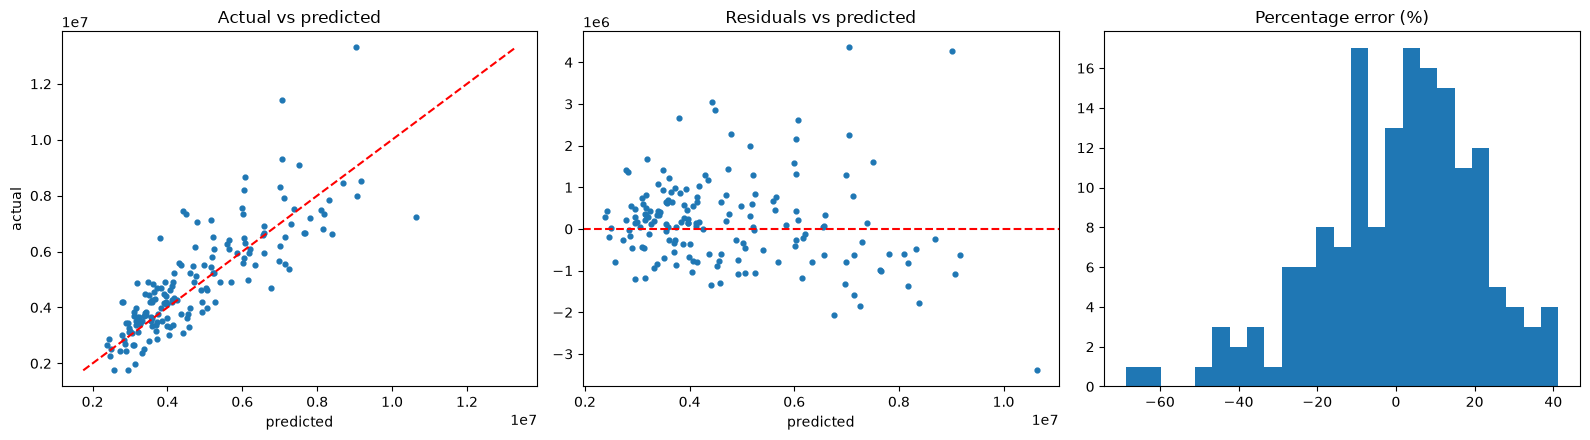

Mean error, top 25% priciest houses: 639184
Mean error, other houses:            2363

      actual      predicted           error  area  bathrooms  stories
4   11410000 3,827,865.0000  4,355,924.0000  7420          1        2
0   13300000 3,818,207.0000  4,276,249.0000  7420          2        3
57   7245000 2,902,199.0000 -3,394,839.0000  9000          2        4
48   7455000 4,120,122.0000  3,036,615.0000  4300          2        2
55   7350000 3,576,489.0000  2,864,423.0000  6000          1        2


In [39]:
import matplotlib.pyplot as plt

resid = yo_test - pred
pct_err = resid / yo_test * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(pred, yo_test, s=12)
lims = [min(pred.min(), yo_test.min()), max(pred.max(), yo_test.max())]
axes[0].plot(lims, lims, 'r--')
axes[0].set_title('Actual vs predicted'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('actual')

axes[1].scatter(pred, resid, s=12); axes[1].axhline(0, color='r', ls='--')
axes[1].set_title('Residuals vs predicted'); axes[1].set_xlabel('predicted')

axes[2].hist(pct_err, bins=25)
axes[2].set_title('Percentage error (%)')
plt.tight_layout(); plt.show()

hi = yo_test >= yo_test.quantile(0.75)
print('Mean error, top 25% priciest houses:', round(resid[hi].mean()))
print('Mean error, other houses:           ', round(resid[~hi].mean()))
print()
worst = resid.abs().sort_values(ascending=False).head(5).index
print(pd.DataFrame({'actual': yo_test[worst], 'predicted': pred[worst].round(0),
                    'error': resid[worst].round(0)}).join(Xo_test.loc[worst, ['area', 'bathrooms', 'stories']]))

In [40]:
pred_s  = pd.Series(pred, index=yo_test.index)
first_s = pd.Series(pred_first, index=yo_test.index)
hi = yo_test >= yo_test.quantile(0.75)

for name, p in [('First model', first_s), ('Final candidate', pred_s)]:
    r = yo_test - p
    print(name, '| mean error top 25%:', round(r[hi].mean()),
          '| MAE top 25%:', round(r[hi].abs().mean()),
          '| MAE others:', round(r[~hi].abs().mean()))

First model | mean error top 25%: 667908 | MAE top 25%: 1166974 | MAE others: 651027
Final candidate | mean error top 25%: 639184 | MAE top 25%: 1358616 | MAE others: 593750
